##Pricing within category

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
cols = ['product_group_name','price']

path = '../data/processed/merged_cleaned_2019.csv'


df = pd.read_csv(path,usecols=cols)

df.head()

,product_group_name,price
0,Garment Upper body,0.045763
1,Garment Lower body,0.033881
2,Garment Lower body,0.061000
3,Garment Upper body,0.015237
4,Garment Full body,0.033881


In [4]:
summary = df.groupby('product_group_name')['price'].agg(['count', 'mean', 'median', 'std'])

summary['skew_gap'] = (summary['mean'] - summary['median']) / summary['median']

summary['variation'] = (summary['std'] / summary['mean']).round(2)

summary.sort_values('variation', ascending=False)
 

 

 

 

,count,mean,median,std,skew_gap,variation
product_group_name,,,,,,
Furniture,456,0.007707,0.005407,0.007227,0.425397,0.94
Garment Upper body,6504648,0.026735,0.022017,0.021470,0.214312,0.80
Accessories,816234,0.015770,0.013542,0.011458,0.164492,0.73
Shoes,399769,0.039099,0.033881,0.025727,0.153997,0.66
Garment Full body,1834274,0.036959,0.033881,0.021203,0.090828,0.57
Garment Lower body,3640857,0.032581,0.032186,0.017012,0.012259,0.52
Garment and Shoe care,64,0.010773,0.013356,0.005291,-0.193369,0.49
Swimwear,1395575,0.022657,0.022017,0.010552,0.029076,0.47
Underwear,1265479,0.020740,0.018712,0.009569,0.108408,0.46


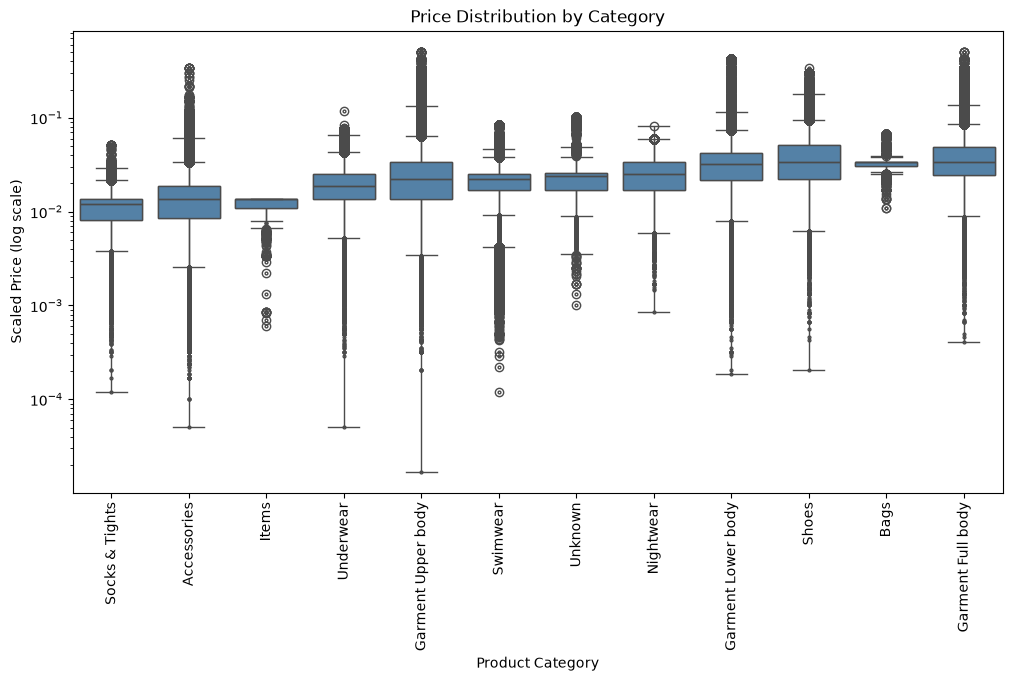

In [ ]:
major_categories = summary[summary['count'] >= 1000].index

major_df = df[df['product_group_name'].isin(major_categories)]

category_order = summary.loc[major_categories].sort_values('median').index

plt.figure(figsize=(12, 6))

sns.boxplot(data=major_df, x='product_group_name', y='price', order=category_order, color='steelblue', fliersize=2)

plt.yscale('log')
plt.xticks(rotation=90)
plt.xlabel('Product Category')
plt.ylabel('Scaled Price (log scale)')
plt.title('Price Distribution by Category')

plt.savefig('../reports/goal3_price_boxplot.png', dpi=150, bbox_inches='tight')

plt.show()

## Findings

Typical prices differ between categories. Socks & Tights has the lowest median, about 0.012. Shoes, Garment Full body and Bags are highest at about 0.034, with Garment Lower body just below.

Garment Upper body has the most uneven prices of the large categories, with a variation of 0.80. Its box is tall and it has a long tail of expensive purchases, which fits its mean sitting 21% above its median.

Items, Bags and Swimwear have narrow boxes, so most of their purchases cost about the same.

Swimwear also has a large cloud of dots far below its box. Many purchases cost much less than the typical swimwear item. The data can't say why, so it could be discounts or genuinely cheap items.

Accessories, Garment Upper body, Garment Lower body, Shoes and Garment Full body have many dots above the box, which means a tail of expensive purchases.

Furniture, Cosmetic, Underwear/nightwear, Garment and Shoe care, and Interior textile are not shown, because each has fewer than 1,000 purchases.

Price is per purchase, so the spread inside a category mixes different products and possible discounts. Prices are scaled, and the 1,000 purchase cutoff is my own choice.